# Midpoint blocking and Gamma comparison

The midpoint is recalculated from per-configuration data, with A+B treated as one concatenated series. The second plot uses saved fit results and Srijit's supplied values; no fits are run.

In [1]:
from pathlib import Path
import sys
import h5py
import numpy as np
import pandas as pd
import pyerrors as pe
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(r"C:/Users/yan14/Documents/ChatGPT/Nsgm/glwc3/project2/07_Nsgm")
sys.path.insert(0, str(ROOT))
import util as yu
import util_codex as yuc

OUTPUT = ROOT / "__codex_ignore/blocking_b64_20261013"
SOURCE = Path.home() / "Desktop/cB211.072.64_732cfg_scalar.h5"
FIT_CSV = OUTPUT / "results.csv"
CHANNELS = ["light", "strange", "charm"]
UNITS = {"light": yu.ens2amul_iso["b"] * yu.ens2aInv["b"],
         "strange": .018267 * yu.ens2aInv["b"], "charm": .23134 * yu.ens2aInv["b"]}
TS, TI = 12, 6
D_LIST = list(range(1, 10))

## Midpoint Inputs

In [2]:
with h5py.File(SOURCE) as f:
    cfgs = f["cfgs"].asstr()[:].tolist()
    c2 = f["disc_c2pt"][:, TS].real.astype(float)
    raw = {}
    for channel, suffix in [("light", "+"), ("strange", "s"), ("charm", "c")]:
        raw[channel] = np.column_stack([
            f[f"disc_gS{suffix}/{TS}"][:, TI].real.astype(float),
            c2, f[f"vev_gS{suffix}"][:].real.astype(float)])
    raw["light"] = np.column_stack([raw["light"],
        f[f"conn_gS+/{TS}"][:, TI].real.astype(float),
        f[f"conn_c2pt/{TS}"][:, TI].real.astype(float)])
assert len(cfgs) == 732 and len(set(cfgs)) == 732
assert cfgs == sorted(cfgs, key=lambda cfg: (cfg[0], int(cfg[1:])))

## Midpoint Errors

Block the primitive measurements before vacuum subtraction. Gamma uses one concatenated series with S=2.

In [3]:
rows, midpoint_gamma = [], {}
for channel in CHANNELS:
    for D in D_LIST:
        jk = yu.jackknife(raw[channel], d=D)
        p, c, v = jk[:, 0], jk[:, 1], jk[:, 2]
        ratio = (p - c * v + jk[:, 3]) / jk[:, 4] if channel == "light" else (p - c * v) / c
        mean, error = yu.jackme(ratio * UNITS[channel])
        rows.append({"D": D, "channel": channel, "mean": float(mean), "stat": float(error)})
    obs = [pe.Obs([column], ["B64"]) for column in raw[channel].T]
    p, c, v = obs[:3]
    ratio = (p - c * v + obs[3]) / obs[4] if channel == "light" else p / c - v
    sigma = ratio * UNITS[channel]
    sigma.gamma_method(S=2)
    midpoint_gamma[channel] = (float(sigma.value), float(sigma.dvalue))
midpoint_table = pd.DataFrame(rows)
display(midpoint_table)
display(pd.DataFrame(midpoint_gamma, index=["mean", "stat"]).T)

,D,channel,mean,stat
0,1,light,24.684871,0.616266
1,2,light,24.684865,0.612377
2,3,light,24.684857,0.628297
3,4,light,24.684848,0.632278
4,5,light,24.683999,0.588525
5,6,light,24.684835,0.629851
6,7,light,24.732054,0.655519
7,8,light,24.732057,0.629295
8,9,light,24.715810,0.651596
9,1,strange,23.132093,2.085418


,mean,stat
light,24.684877,0.620683
strange,23.132098,2.386940
charm,103.763719,40.118903


## Plotting

In [4]:
def plot_comparison(table, reference, tick, face, stem, star_size=9):
    labels = {"light": r"$\sigma_{\pi N}$", "strange": r"$\sigma_s$", "charm": r"$\sigma_c$"}
    with plt.rc_context(yuc.paper_style({"axes.labelsize": 12, "xtick.labelsize": 10,
        "ytick.labelsize": 10, "lines.markersize": 4, "errorbar.capsize": 3})):
        fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6), sharex=True)
        for column, channel in enumerate(CHANNELS):
            data = table[table["channel"] == channel]
            top, bottom = axes[:, column]
            mean, error = reference[channel]
            top.errorbar(data["D"], data["mean"], data["stat"], fmt="none",
                color="red", linewidth=1, capsize=3)
            top.plot(data["D"], data["mean"], "o", color="red", mfc="white", zorder=4)
            top.errorbar(10, mean, error, fmt="*", color="black", mfc=face, mec="black",
                markersize=star_size, linewidth=1, capsize=3, zorder=5)
            lo = min((data["mean"] - data["stat"]).min(), mean - error)
            hi = max((data["mean"] + data["stat"]).max(), mean + error)
            padding = .40 * (hi - lo)
            top.set_ylim(lo - padding, hi + padding)
            bottom.plot(data["D"], data["stat"], color="blue", marker="o", linestyle="-", linewidth=1)
            bottom.axhline(error, color="black", linestyle="--", linewidth=1)
            bottom.plot(10, error, "*", color="black", mfc=face, mec="black",
                markersize=star_size, zorder=5)
            lo, hi = min(data["stat"].min(), error), max(data["stat"].max(), error)
            padding = .20 * (hi - lo)
            bottom.set_ylim(max(0, lo - padding), hi + padding)
            top.set_ylabel(labels[channel] + " [MeV]")
            bottom.set_ylabel("Error [MeV]")
            bottom.set_xlabel(r"$D$")
            for axis in [top, bottom]:
                axis.set_xticks([*D_LIST, 10], [*[str(d) for d in D_LIST], tick])
                axis.grid(False)
        fig.tight_layout()
        fig.savefig(OUTPUT / (stem + ".pdf"))
        fig.savefig(OUTPUT / (stem + ".png"), dpi=180)
        display(fig)
        plt.close(fig)

## Midpoint Plot

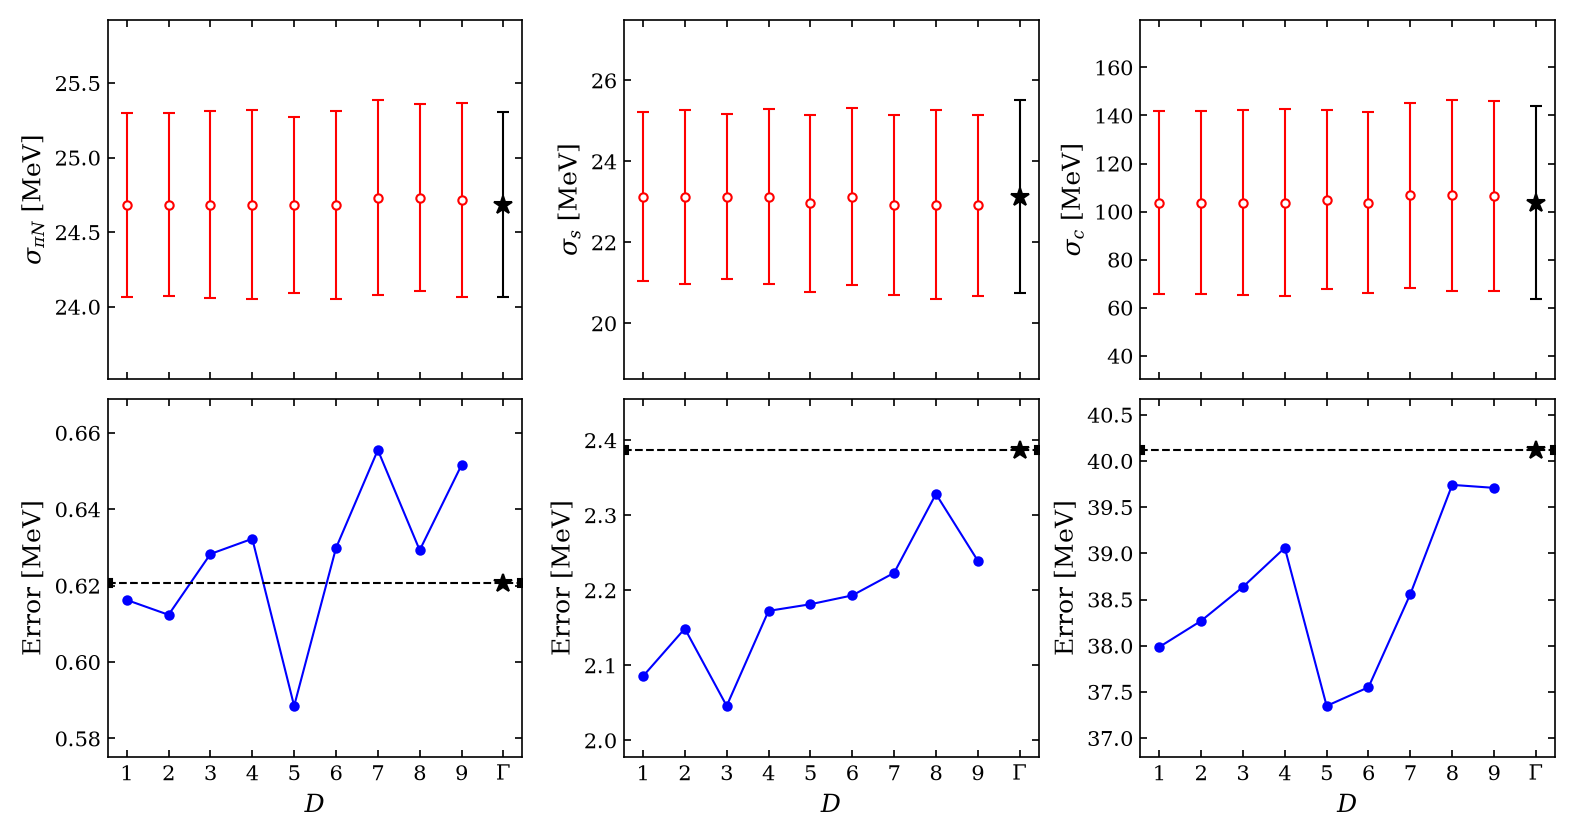

In [5]:
plot_comparison(midpoint_table, midpoint_gamma, r"$\Gamma$", "black",
    "sigma_midpoints_vs_block_size_concatenated_gamma")

## Saved Fits and Srijit

This cell plots existing fitted values and statistical errors. The open star is Srijit's supplied Gamma-method result, not a new fit.

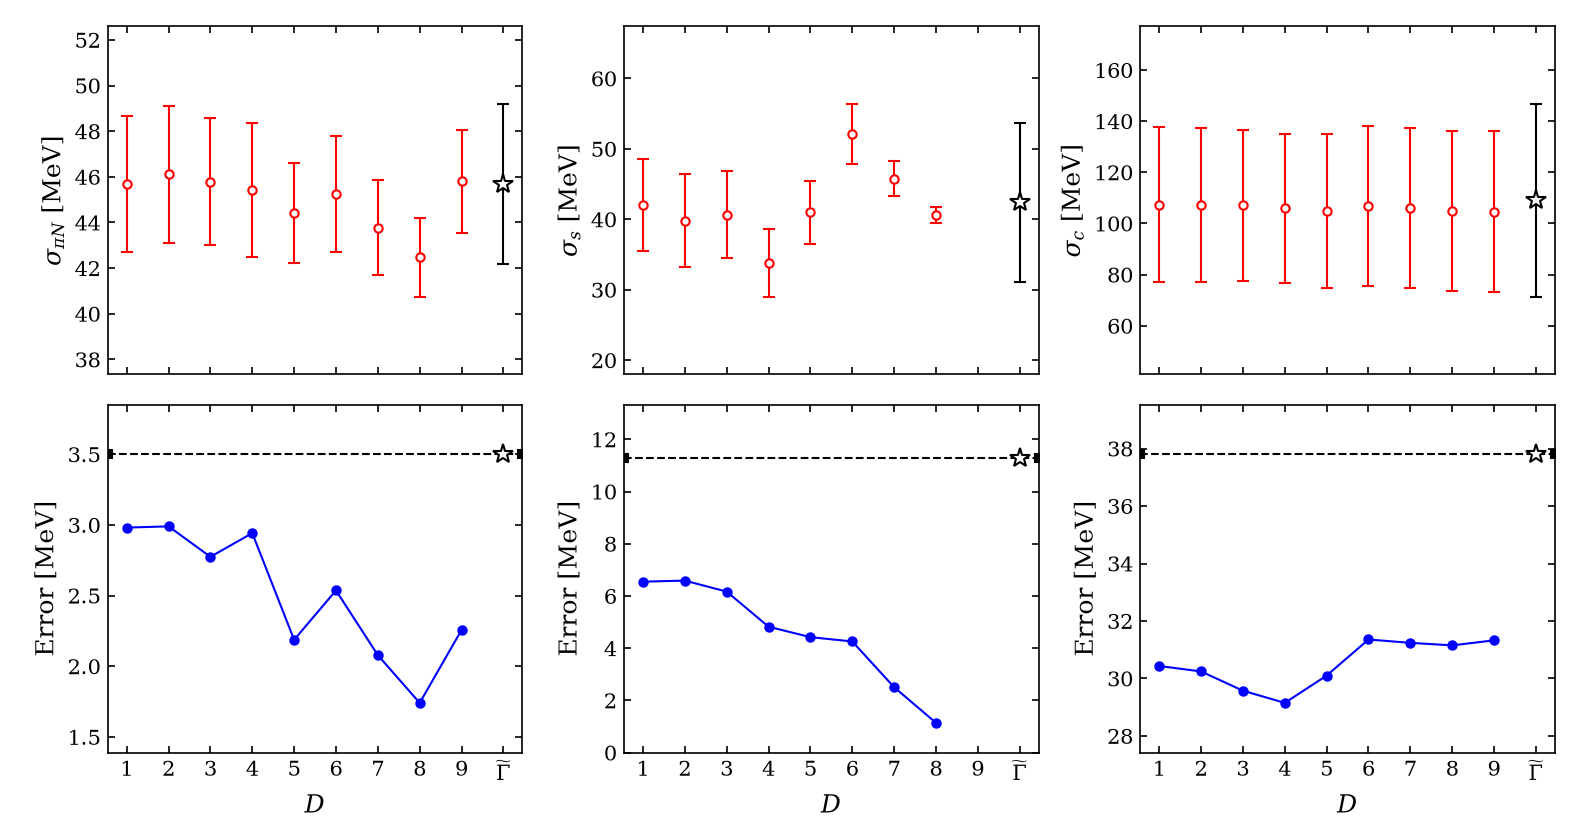

In [6]:
fit_table = pd.read_csv(FIT_CSV)
srijit = {"light": (45.7, 3.5), "strange": (42.4, 11.3), "charm": (109.0, 37.8)}
plot_comparison(fit_table, srijit, r"$\widetilde{\Gamma}$", "white",
    "sigma_fit_statistics_vs_block_size_srijit_only", star_size=10)

## Fits With Fixed D=1 Covariances

Both two-point and three-point covariance matrices are estimated at D=1 and held fixed across all blocking sizes and refits. Raw measurements are reblocked before vacuum subtraction, and the two-point inputs are refitted and propagated at each D. The paper's models and ranges are unchanged: light (12,2,20), strange (10,2,22), charm (12,4,24), and two-point times 8..30. Charm retains diagonal fit weighting. The open star remains Srijit's supplied value.

D=1, light: 45.71 +/- 2.98 MeV
D=1, strange: 42.06 +/- 6.55 MeV
D=1, charm: 107.40 +/- 30.43 MeV
D=2, light: 45.71 +/- 3.00 MeV
D=2, strange: 42.06 +/- 6.92 MeV
D=2, charm: 107.40 +/- 30.45 MeV
D=3, light: 45.71 +/- 2.97 MeV
D=3, strange: 42.06 +/- 7.26 MeV
D=3, charm: 107.40 +/- 29.69 MeV
D=4, light: 45.71 +/- 2.98 MeV
D=4, strange: 42.07 +/- 7.37 MeV
D=4, charm: 107.40 +/- 29.56 MeV
D=5, light: 45.40 +/- 2.60 MeV
D=5, strange: 41.83 +/- 7.39 MeV
D=5, charm: 105.69 +/- 30.06 MeV
D=6, light: 45.71 +/- 2.97 MeV
D=6, strange: 42.07 +/- 7.21 MeV
D=6, charm: 107.40 +/- 32.07 MeV
D=7, light: 45.21 +/- 2.82 MeV
D=7, strange: 41.44 +/- 7.73 MeV
D=7, charm: 106.78 +/- 31.29 MeV
D=8, light: 45.21 +/- 2.80 MeV
D=8, strange: 41.44 +/- 6.98 MeV
D=8, charm: 106.78 +/- 31.72 MeV
D=9, light: 45.27 +/- 2.70 MeV
D=9, strange: 41.70 +/- 7.99 MeV
D=9, charm: 105.90 +/- 31.42 MeV


,D,channel,mean,stat,bins,points,chi2_dof
0,1,light,45.705683,2.981436,732,35,1.035309
1,1,strange,42.061238,6.549747,732,88,1.158839
2,1,charm,107.398639,30.434188,732,75,0.446871
3,2,light,45.705899,3.001936,366,35,1.035472
4,2,strange,42.062678,6.918134,366,88,1.158897
5,2,charm,107.398443,30.449079,366,75,0.447266
6,3,light,45.706115,2.968864,244,35,1.035627
7,3,strange,42.064386,7.257524,244,88,1.158948
8,3,charm,107.398162,29.688420,244,75,0.447603
9,4,light,45.706371,2.984097,183,35,1.035808


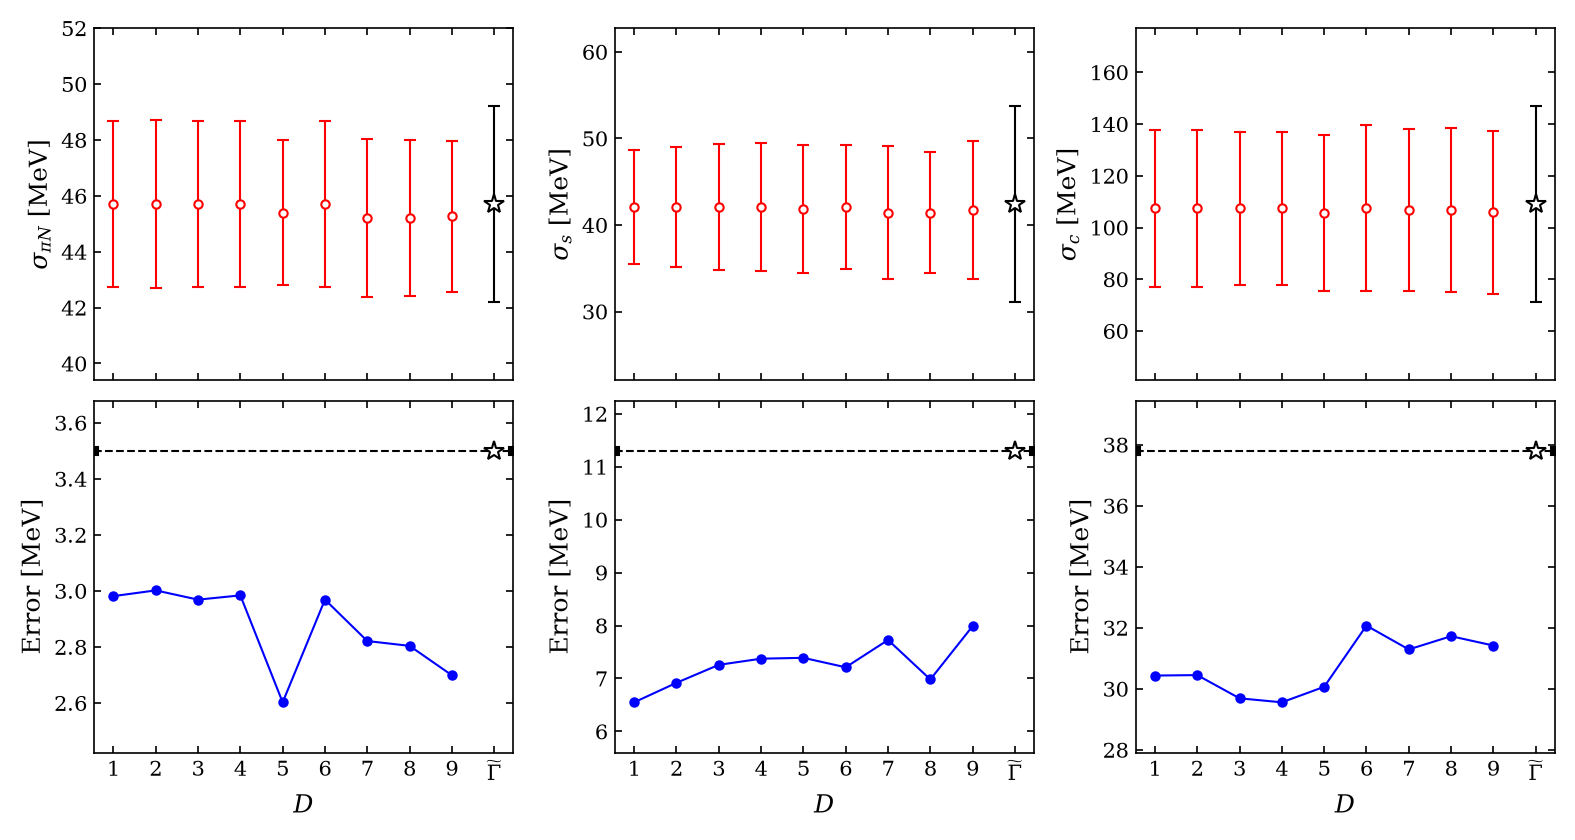

In [7]:
def fit_fixed_covariance(fitfunc, y_jk, covariance, start, extra=None):
    current_covariance = yu.jackmec(y_jk)[2]
    assert np.all(current_covariance != 0)
    mask = covariance / current_covariance
    np.testing.assert_allclose(current_covariance * mask, covariance, rtol=1e-12, atol=1e-18)
    return yu.jackfit(fitfunc, y_jk, start, mask=mask, parsExtra_jk=extra)

fit_setup = {"light": (list(range(12, 21, 2)), 2),
             "strange": (list(range(10, 23)), 2),
             "charm": (list(range(12, 25)), 4)}
with h5py.File(SOURCE) as f:
    assert f["cfgs"].asstr()[:].tolist() == cfgs
    fit_raw_c2 = f["disc_c2pt"][:].real.astype(float)
    fit_raw_vev, fit_raw_c3 = {}, {}
    for channel, suffix in [("light", "+"), ("strange", "s"), ("charm", "c")]:
        fit_raw_vev[channel] = f[f"vev_gS{suffix}"][:].real.astype(float)
        fit_raw_c3[channel] = {t: f[f"disc_gS{suffix}/{t}"][:].real.astype(float)
                               for t in fit_setup[channel][0]}
    fit_raw_connected = {t: f[f"conn_gS+/{t}"][:].real.astype(float)
                         for t in fit_setup["light"][0]}
    fit_raw_matched = {t: f[f"conn_c2pt/{t}"][:, 0].real.astype(float)
                       for t in fit_setup["light"][0]}

d1_seeds = yu.load_pkl(OUTPUT / "fit_samples.pkl")[1]
two_point_times = np.arange(8, 31)
covariance_3pt_D1 = {}
fixed_fit_rows, fixed_two_point_fits, fixed_standard_fits = [], {}, {}

for D in D_LIST:
    c2_jk = yu.jackknife(fit_raw_c2, d=D)
    meff_jk = yu.jackmap(yu.c2pt2meff, c2_jk)[:, two_point_times]
    if D == 1:
        covariance_2pt_D1 = yu.jackmec(meff_jk)[2]
    two_point_fit = fit_fixed_covariance(
        lambda p: yu.func_meff_2st(two_point_times, *p), meff_jk,
        covariance_2pt_D1, np.mean(d1_seeds["nucleon"][0], axis=0))
    assert two_point_fit[3] == 0
    fixed_two_point_fits[D] = two_point_fit
    fixed_standard_fits[D] = {}

    for channel in CHANNELS:
        tfs, cut = fit_setup[channel]
        vev_jk = yu.jackknife(fit_raw_vev[channel], d=D)
        ratio = {}
        for t in tfs:
            numerator = yu.jackknife(fit_raw_c3[channel][t], d=D)
            numerator -= c2_jk[:, t, None] * vev_jk[:, None]
            if channel == "light":
                numerator += yu.jackknife(fit_raw_connected[t], d=D)
                denominator = yu.jackknife(fit_raw_matched[t], d=D)
            else:
                denominator = c2_jk[:, t]
            ratio[t] = numerator / denominator[:, None]
        sym = yu.symmetrizeRatio(ratio)
        y_jk = np.concatenate([sym[t][:, cut:t // 2 + 1] for t in tfs], axis=1)
        if D == 1:
            covariance = yu.jackmec(y_jk)[2]
            covariance_3pt_D1[channel] = (np.diag(np.diag(covariance))
                                         if channel == "charm" else covariance)
        if channel == "charm":
            fitfunc = lambda p: np.full(y_jk.shape[1], p[0])
            extra = None
        else:
            ts, ti = np.array([(t, i) for t in tfs for i in range(cut, t // 2 + 1)]).T
            fitfunc = lambda p: yu.func_ratioSYM_2st_0ra11(ts, ti, *p)
            extra = two_point_fit[0][:, 1:3]
        fit = fit_fixed_covariance(fitfunc, y_jk, covariance_3pt_D1[channel],
            np.mean(d1_seeds[channel]["standard"][0], axis=0), extra)
        assert fit[3] == 0
        fixed_standard_fits[D][channel] = fit
        mean, error = yu.jackme(fit[0][:, 0] * UNITS[channel])
        fixed_fit_rows.append({"D": D, "channel": channel, "mean": float(mean),
            "stat": float(error), "bins": len(y_jk), "points": y_jk.shape[1],
            "chi2_dof": float(np.mean(fit[1]) / fit[2])})
        print(f"D={D}, {channel}: {mean:.2f} +/- {error:.2f} MeV")

fixed_fit_table = pd.DataFrame(fixed_fit_rows)
fixed_fit_table.to_csv(OUTPUT / "fit_results_fixed_D1_covariance.csv", index=False)
display(fixed_fit_table)
plot_comparison(fixed_fit_table, srijit, r"$\widetilde{\Gamma}$", "white",
    "sigma_fit_statistics_vs_block_size_fixed_D1_covariance_srijit", star_size=10)
